# FIN 6465 — Chapter 5 Mini-Project
## Integrating the Three Statements: Cash Flow + Tie-Outs

**Financial Modeling with Python — Chapter 5: Constructing the Cash Flow Statement and Integrating the Three Statements**

> **Guiding question:** Given the firm's income statement and the Chapter 4 schedules, does your integrated model satisfy $\Delta Cash_t = CFO_t + CFI_t + CFF_t\,(+\,OtherCash_t)$ and $Assets_t = Liabilities_t + Equity_t$ in every period, without a hidden cash plug?

**Due:** Friday, November 13, 11:59 PM ET &nbsp;|&nbsp; **Points:** 10 &nbsp;|&nbsp; **Submit:** this notebook (`.ipynb`) and the five files it exports, in Canvas → Assignments

Read the **Chapter 5 Mini-Project Brief (PDF)** on the Week 5 page first. Section numbers in this notebook match the brief.

### Student information

| | |
|---|---|
| **Name** | Caleb D'Antonio |
| **UF email** | c.dantonio@ufl.edu |
| **Section** | R222 (4:05 PM) |
| **Team members** | Casey Foran, Sophia Parra, Aman Vyas |
| **Team company (ticker)** | Quanta Services, Inc. (PWR) |
| **Generative AI tools used** | Claude |

**Collaboration.** Your team works on the same company and may work through the mini-project together, but **each student submits their own notebook and is graded individually**. Write your own code and your own interpretations.

**Generative AI.** You may use AI tools to understand concepts and debug code if you disclose it in the AI-use reflection. Be ready to explain every line you submit: **next Tuesday's quiz includes questions on this mini-project.**

### How to use this notebook

1. **You design the code.** Each section states the brief's formulas and the **required output** (exact names and columns). The provided cells use those outputs, so match them exactly.
2. This week everything runs through **one function**, `run_three_statement_model()` (Section 2.8). Changing a driver must require only one call to it.
3. Answer every ✍️ prompt, and write your summary in the `SUMMARY` cell.
4. Before submitting, run **Kernel → Restart Kernel and Run All Cells**. The notebook must run top to bottom without errors.
5. Upload six files in Canvas: **`FIN6465_MP5_LastName_FirstName.ipynb`** and the `_cash_flow.csv`, `_balance_sheet.csv`, `_integrity.csv`, `_metadata.json`, and `_summary.md` files that Section 2.9 exports.

---
## Setup

Run these cells to check your environment and load the FMP helper. The key setup is the same as Week 1; if `FMP_API_KEY` is already set, nothing else is needed.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

print(f"Python     {sys.version.split()[0]}")
print(f"NumPy      {np.__version__}")
print(f"pandas     {pd.__version__}")
print(f"Matplotlib {matplotlib.__version__}")

Python     3.13.9
NumPy      2.1.3
pandas     2.2.3
Matplotlib 3.10.0


In [2]:
import os, json
from pathlib import Path
from getpass import getpass
import requests

FMP_BASE = "https://financialmodelingprep.com/stable"
CACHE_DIR = Path("fmp_cache")
CACHE_DIR.mkdir(exist_ok=True)

FMP_API_KEY = os.environ.get("FMP_API_KEY") or getpass("Paste your team's FMP API key (input is hidden): ")


def fmp_get(endpoint, symbol, period="quarter", limit=24, use_cache=True):
    """Fetch one FMP endpoint for a ticker and return a DataFrame (most recent period first).

    Quarterly statements are the course default (at least 20 quarters = 5 years);
    pass period="annual" only for the annual 10-K cross-check.

    endpoint : "income-statement", "balance-sheet-statement", or "cash-flow-statement"
    symbol   : ticker, e.g. "AAPL"
    period   : "quarter" (10-Q, plus the fiscal Q4 from the 10-K; default) or "annual" (10-K)
    limit    : number of periods to return (default 24 quarters)
    """
    symbol = symbol.upper().strip()
    cache_file = CACHE_DIR / f"{symbol}_{endpoint}_{period}_{limit}.json"
    if use_cache and cache_file.exists():
        data = json.loads(cache_file.read_text())
    else:
        params = {"symbol": symbol, "period": period, "limit": limit, "apikey": FMP_API_KEY}
        response = requests.get(f"{FMP_BASE}/{endpoint}", params=params, timeout=30)
        if response.status_code != 200:
            raise RuntimeError(f"FMP returned HTTP {response.status_code}: {response.text[:300]}")
        data = response.json()
        if isinstance(data, dict):   # FMP reports problems as a JSON object
            raise RuntimeError(f"FMP error for {symbol}: {data}")
        if not data:
            raise ValueError(f"No data returned for {symbol} ({endpoint}). Check the ticker.")
        cache_file.write_text(json.dumps(data))
    return pd.DataFrame(data)


def pick(df, field, row=0):
    """Return one value from an FMP statement: `field` in row `row` (0 = most recent period)."""
    if field not in df.columns:
        raise KeyError(f"'{field}' is not a column. Look at df.columns to find the right field name.")
    value = df.iloc[row][field]
    if pd.isna(value):
        raise ValueError(f"'{field}' is empty for row {row}. Check the 10-Q (or the 10-K for a fiscal Q4) and choose another field.")
    return float(value)

print("FMP helper ready. API key loaded:", bool(FMP_API_KEY))

Paste your team's FMP API key (input is hidden):  ········


FMP helper ready. API key loaded: True


### Quarterly helpers (provided)

Flows (revenue, COGS, D&A, net income, CapEx, dividends, CFO) are **summed** across quarters; stocks (balance-sheet items) are read at a **quarter-end**. `ttm()` gives trailing-twelve-month sums of a flow, and `to_fiscal_years()` builds complete fiscal years from the quarters (flows summed, stocks at the fiscal Q4 balance).

In [3]:
# ---- Quarterly helpers (provided) -------------------------------------------------
# Every mini-project uses at least five years of QUARTERLY data (20 quarters of 10-Q/10-K
# filings). Flows (revenue, net income, CFO, CapEx, ...) are summed across quarters;
# stocks (balance-sheet items) are read at a quarter-end date.
MIN_QUARTERS = 20   # course requirement: at least 5 years x 4 quarters


def quarterly_frame(df, scale=1.0):
    """Return an FMP quarterly statement sorted oldest -> newest, indexed by labels like 'FY2025Q3'.

    Adds three columns: fiscal_year (int), fiscal_q (1-4) and period_end (Timestamp).
    Numeric columns are divided by `scale` (1e6 -> USD millions); ratios such as EPS are not
    special-cased, so divide only the statements you need in dollars.
    """
    out = df.copy()
    if "fiscalYear" in out.columns:
        fy = out["fiscalYear"].astype(int)
    else:
        fy = pd.to_datetime(out["date"]).dt.year
    q = out["period"].astype(str).str.upper().str.replace("Q", "", regex=False)
    if not q.isin(["1", "2", "3", "4"]).all():
        raise ValueError("Expected period values Q1-Q4. Did you call fmp_get(..., period='quarter')?")
    out["fiscal_year"] = fy.values
    out["fiscal_q"] = q.astype(int).values
    out["period_end"] = pd.to_datetime(out["date"]).values
    out = out.sort_values(["fiscal_year", "fiscal_q"])
    out.index = [f"FY{y}Q{qq}" for y, qq in zip(out["fiscal_year"], out["fiscal_q"])]
    keep = {"fiscal_year", "fiscal_q", "period_end"}
    num = [c for c in out.columns if c not in keep and pd.api.types.is_numeric_dtype(out[c])]
    out[num] = out[num] / scale
    return out


def check_quarters(q, min_quarters=MIN_QUARTERS):
    """PASS/FAIL detail for the quarterly coverage rule: enough quarters, unique, no gaps."""
    n = len(q)
    unique = q.index.is_unique
    seq = q["fiscal_year"] * 4 + q["fiscal_q"]
    no_gaps = bool((seq.diff().dropna() == 1).all())
    passed = (n >= min_quarters) and unique and no_gaps
    detail = f"{n} quarters ({q.index[0]} to {q.index[-1]}); unique={unique}; consecutive={no_gaps}"
    return passed, detail


def ttm(series):
    """Trailing-twelve-month sum of a quarterly FLOW series (NaN until four quarters exist)."""
    return series.rolling(4).sum()


def to_fiscal_years(q, flow_cols=(), stock_cols=()):
    """Aggregate quarters to complete fiscal years: flows are summed, stocks use the Q4 value.

    Only fiscal years with all four quarters are returned, so a partial current year is dropped.
    """
    complete = q.groupby("fiscal_year")["fiscal_q"].nunique()
    years = complete[complete == 4].index
    qq = q[q["fiscal_year"].isin(years)]
    parts = []
    if flow_cols:
        parts.append(qq.groupby("fiscal_year")[list(flow_cols)].sum())
    if stock_cols:
        parts.append(qq[qq["fiscal_q"] == 4].set_index("fiscal_year")[list(stock_cols)])
    out = pd.concat(parts, axis=1)
    out.index.name = "fiscal_year"
    return out

### Settings and drivers

Copy your driver assumptions from Week 4 so the model starts from the same base case.

In [4]:
# ===================== SETTINGS =====================
SYMBOL = "PWR"
FILE_STEM = "FIN6465_MP5_D'Antonio_Caleb"
MP3_FORECAST_CSV = "FIN6465_MP3_D'Antonio_Caleb_forecast.csv"
MP4_BALANCE_CSV = "FIN6465_MP4_D'Antonio_Caleb_balance_sheet_full.csv"
N_QUARTERS = 24              # >= 20 required (5 years); 24 guarantees 5 complete fiscal years
SCALE = 1e6
UNITS = "USD millions"
DAYS = 365
ATOL = 1e-6                  # tie-out tolerance, in UNITS

# ===================== DRIVERS (from Week 4) =====================
SCENARIO = "base"
MODEL_VERSION = "1.0"
DRIVERS = {
    "dso": 105.0,                   # receivables incl. contract assets; Q4 mean 105.6
    "dio": 4.5,                     # Q4 mean 3.8, rising trend to 5.5 in FY2025
    "dpo": 38.5,                    # Q4 mean 38.5
    "deferred_pct_revenue": 0.10,   # contract liabilities / revenue; between Q4 mean 8.2% and FY2025 11.5%
    "capex_pct_revenue": 0.030,     # top of 2.1-3.0% historical range
    "payout_ratio": 0.06,           # dividends / net income; FY2024-FY2025 5.9-6.0%
    "interest_rate": 0.048,         # on total debt incl. operating leases; FY2025 4.8%
    "borrowings": [0.0] * 5,        # gross new debt by forecast year (positive magnitudes)
    "repayments": [0.0] * 5,        # gross debt repaid by forecast year (positive magnitudes)
    "equity_issued": [0.0] * 5,
    "equity_repurchased": [0.0] * 5,
}

---
## 2.1 Data Ingestion and Conventions

The cell below (provided) loads:
- `is_forecast`: your Week 3 forecast (revenue, COGS, EBIT, D&A, EBT, tax, net income);
- `bs_week4`: your Week 4 balance sheet, history and forecast (its forecast cash is the Chapter 4 plug, used only as a cross-check);
- `opening_bs`: the last actual year of that balance sheet, the starting point for the forecast. It is the **Q4 balance sheet of the last complete fiscal year** (Week 4 builds its history from quarterly statements, with balances at fiscal Q4);
- `cf_q`: FMP's reported **quarterly** cash flow statements (`N_QUARTERS`, at least 20 quarters);
- `cf_hist`: those quarters aggregated to **complete fiscal years** with `to_fiscal_years`, for the historical rows of your export. CFO, CFI, CFF, OtherCash, and the net change in cash are flows (the sum of the four quarters); `cash_end` is the fiscal Q4 ending cash and `cash_begin` the fiscal Q1 beginning cash. A partial current fiscal year is dropped.

**Sign conventions:** cash inflows are positive and outflows negative in the cash flow statement; balance sheet levels are positive; schedule inputs (CapEx, borrowings, repayments, dividends, equity issued or repurchased) are positive magnitudes, with signs applied when the cash flow statement is assembled. Interest paid stays in CFO (inside net income); dividends are in CFF.

In [5]:
def year_index(labels):
    """Convert labels like 'FY2026E' to integer years."""
    return pd.Index(labels).str[2:6].astype(int)

mp3 = pd.read_csv(MP3_FORECAST_CSV, index_col=0)
is_forecast = mp3[mp3.index.str.endswith("E")].copy()
is_forecast.index = year_index(is_forecast.index)

bs_week4 = pd.read_csv(MP4_BALANCE_CSV, index_col=0)
last_actual_label = [i for i in bs_week4.index if i.endswith("A")][-1]
bs_week4.index = year_index(bs_week4.index)
opening_bs = bs_week4.loc[int(last_actual_label[2:6])]

cf = fmp_get("cash-flow-statement", SYMBOL, period="quarter", limit=N_QUARTERS)
CF_FIELDS = {"cfo": "operatingCashFlow", "cfi": "netCashProvidedByInvestingActivities",
             "cff": "netCashProvidedByFinancingActivities", "other_cash": "effectOfForexChangesOnCash",
             "net_change_in_cash": "netChangeInCash", "cash_begin": "cashAtBeginningOfPeriod",
             "cash_end": "cashAtEndOfPeriod"}
missing = [f for f in CF_FIELDS.values() if f not in cf.columns]
if missing:
    raise KeyError(f"Edit CF_FIELDS: {missing} not in {list(cf.columns)}")
cf_q = quarterly_frame(cf)
cf_q = cf_q[["fiscal_year", "fiscal_q", "period_end"]].assign(
    **{k: cf_q[v].astype(float) / SCALE for k, v in CF_FIELDS.items()})

# Fiscal years from quarters: flows summed, ending cash at fiscal Q4, beginning cash at fiscal Q1
CF_FLOWS = ["cfo", "cfi", "cff", "other_cash", "net_change_in_cash"]
cf_hist = to_fiscal_years(cf_q, flow_cols=CF_FLOWS, stock_cols=["cash_end"])
cf_hist["cash_begin"] = cf_q[cf_q["fiscal_q"] == 1].set_index("fiscal_year")["cash_begin"]
cf_hist = cf_hist[list(CF_FIELDS)]
last_actual_year = int(opening_bs.name)
if cf_hist.index[-1] > last_actual_year:
    print(f"Note: FY{cf_hist.index[-1]} is complete in FMP but not in your Week 4 history; kept through FY{last_actual_year} only")
cf_hist = cf_hist[cf_hist.index <= last_actual_year]
partial = cf_q[cf_q["fiscal_year"] > last_actual_year]

print(f"Quarters: {cf_q.index[0]}-{cf_q.index[-1]} ({len(cf_q)})  |  Complete fiscal years: FY{cf_hist.index[0]}-FY{cf_hist.index[-1]}")
if len(partial):
    print(f"Quarters after FY{last_actual_year} ({', '.join(partial.index)}): year-to-date cross-check only, not in the annual model")
print(f"Opening balance sheet: FY{opening_bs.name} (fiscal Q4) | Forecast: FY{is_forecast.index[0]}-FY{is_forecast.index[-1]} ({UNITS})")
display(opening_bs.to_frame("opening").round(1).T)
display(cf_hist.T.round(1))

Quarters: FY2020Q3-FY2026Q2 (24)  |  Complete fiscal years: FY2021-FY2025
Quarters after FY2025 (FY2026Q1, FY2026Q2): year-to-date cross-check only, not in the annual model
Opening balance sheet: FY2025 (fiscal Q4) | Forecast: FY2026-FY2030 (USD millions)


,cash,ar,inventory,other_current_assets,ppe_net,other_noncurrent_assets,ap,deferred_revenue,other_current_liabilities,debt,other_noncurrent_liabilities,retained_earnings,other_equity,total_assets,total_liabilities,total_equity,cash_plug,balance_error,cash_plug_flag
opening,439.508,8369.277,370.372,724.26,3856.018,11167.466,2832.6,3258.465,1861.235,6418.954,1527.773,6673.99,2353.884,24926.901,15899.027,9027.874,NaN,0.0,False


fiscal_year,2021,2022,2023,2024,2025
cfo,582.4,1130.3,1576.0,2081.2,2230.0
cfi,-2898.6,-617.2,-989.6,-2294.3,-3831.0
cff,2360.9,-311.1,268.5,-305.6,1275.0
other_cash,0.4,-0.7,7.0,-30.3,21.4
net_change_in_cash,45.1,201.3,861.8,-549.0,-304.6
cash_begin,186.8,231.9,433.2,1295.0,746.0
cash_end,231.9,433.2,1293.9,746.0,440.9


✍️ **Cash definition and alignment:** Your Week 4 balance sheet defines cash as cash **and short-term investments**; FMP's historical cash flow statement uses cash and equivalents (often including restricted cash). State the definition your forecast uses and how the two differ for your company in the last actual year (check the 10-K for the fiscal Q4 balance sheet; name the filing, the statement, and the line item). Do the Week 3 and Week 4 years align, and does the forecast start the year after the last complete fiscal year?

The forecast defines cash as cash and short-term investments from the Week 4 balance sheet: 439.5 at FY2025 fiscal Q4. Quanta holds no short-term investments, so this equals “Cash and cash equivalents” on the Consolidated Balance Sheets in the FY2025 Form 10-K. FMP’s cash flow statement ends FY2025 at 440.9 because it reconciles cash, cash equivalents, and restricted cash; the 1.4 difference is restricted cash, which my balance sheet carries inside other current assets. As a result, FY2025A Cash_End (440.9) does not equal FY2026E Cash_Begin (439.5) in the export. The years align: Week 4 history covers FY2021–FY2025, the Week 3 forecast covers FY2026–FY2030, and the forecast starts the year after the last complete fiscal year.

---
## 2.2–2.5 Builders

Write one function for each step below, then call them from `run_three_statement_model()` in Section 2.8. You may reuse your Week 4 code for the schedules (working capital, PP&E, equity, debt).

**2.2 CFO (indirect method):** $CFO_t = NetIncome_t + D\&A_t + WC\_CashImpact_t + OtherAdj_t$, where $WC\_CashImpact_t = -\Delta NWC_t$ (operating current assets up = cash out; operating current liabilities up = cash in). In the first forecast year, measure ΔNWC from the opening balance sheet. `other_adj` is 0 unless you label a specific reclassification.

**2.3 CFI:** $CFI_t = -CapEx_t + ProceedsFromSale_t + OtherInvesting_t$ (CapEx stored positive; sign applied here).

**2.4 CFF:** $CFF_t = Borrowings_t - Repayments_t + EquityIssued_t - EquityRepurchased_t - Dividends_t + OtherFinancing_t$, and the debt roll-forward must reconcile, $\Delta Debt_t = Borrowings_t - Repayments_t$; have your CFF builder raise an error if it does not.

**2.5 Cash assembly, in order:** $\Delta Cash_t = CFO_t + CFI_t + CFF_t + OtherCash_t$; $Cash_t = Cash_{t-1} + \Delta Cash_t$ (cumulative sum from the opening cash); insert cash into the balance sheet; $BalanceError_t = Assets_t - Liabilities_t - Equity_t$.

> **Cash is an output, not a plug.** Do not compute cash as a residual anywhere. Any imbalance must surface in `balance_error`.

**Required outputs** (each indexed by forecast fiscal year):
- **`cash_flow`** with columns `net_income`, `da`, `wc_cash_impact`, `other_adj`, `cfo`, `capex`, `proceeds_from_sale`, `other_investing`, `cfi`, `borrowings`, `repayments`, `equity_issued`, `equity_repurchased`, `dividends`, `other_financing`, `cff`, `other_cash`, `net_change_in_cash`, `cash_begin`, `cash_end`. Outflows are negative except `capex`, `repayments`, `equity_repurchased`, and `dividends`, which are stored as positive magnitudes and subtracted in the totals.
- **`balance_sheet`** with the Week 4 columns (`cash` through `other_equity`) plus `total_assets`, `total_liabilities`, `total_equity`, and `balance_error`.
- **Equity:** if you model issuance or repurchases, keep them in `other_equity` so equity reconciles.

In [6]:
IS_COLS = {"revenue": "revenue", "cogs": "cogs", "ebit": "ebit", "da": "da",
           "ebt": "ebt", "tax": "tax", "net_income": "net_income"}

BS_ASSETS_EX_CASH = ["ar", "inventory", "other_current_assets", "ppe_net", "other_noncurrent_assets"]
BS_LIABILITIES = ["ap", "deferred_revenue", "other_current_liabilities", "debt", "other_noncurrent_liabilities"]
BS_EQUITY = ["retained_earnings", "other_equity"]


def check_opening_balance(opening_bs, atol=ATOL):
    """Opening balance sheet must balance before anything is rolled forward."""
    gap = (opening_bs[["cash"] + BS_ASSETS_EX_CASH].sum() - opening_bs[BS_LIABILITIES].sum()
           - opening_bs[BS_EQUITY].sum())
    if abs(gap) >= atol:
        raise ValueError(f"Opening balance sheet (FY{opening_bs.name}) is off by {gap:.6f}. "
                         "Load an unrounded Week 4 export; do not plug the difference.")
    return gap


def prepare_income_statement(is_forecast):
    """Step 1: standardize the Week 3 income statement and check the year index."""
    missing = [c for c in IS_COLS.values() if c not in is_forecast.columns]
    if missing:
        raise KeyError(f"Edit IS_COLS: {missing} not in {list(is_forecast.columns)}")
    is_ = is_forecast[list(IS_COLS.values())].rename(columns={v: k for k, v in IS_COLS.items()}).astype(float)
    if not (is_.index.is_monotonic_increasing and is_.index.is_unique):
        raise ValueError("Income statement years must be unique and sorted")
    if is_.isna().any().any():
        raise ValueError("Income statement has missing values")
    is_["tax_rate"] = is_["tax"] / is_["ebt"]
    return is_


def flow_series(drivers, key, years):
    """Driver list (positive magnitudes) -> Series on the forecast years."""
    vals = np.asarray(drivers[key], dtype=float)
    if len(vals) != len(years):
        raise ValueError(f"drivers['{key}'] needs {len(years)} values, got {len(vals)}")
    if (vals < 0).any():
        raise ValueError(f"drivers['{key}'] must be positive magnitudes; signs are applied at assembly")
    return pd.Series(vals, index=years)


def build_schedules(is_, opening_bs, drivers, days=DAYS):
    """Step 2: Week 4 schedules (working capital, PP&E, equity, debt). All flows stored positive."""
    y = is_.index
    # Working capital: days and %-of-revenue drivers; other current items held at opening
    wc = pd.DataFrame(index=y)
    wc["ar"] = is_["revenue"] * drivers["dso"] / days
    wc["inventory"] = is_["cogs"] * drivers["dio"] / days
    wc["other_current_assets"] = opening_bs["other_current_assets"]
    wc["ap"] = is_["cogs"] * drivers["dpo"] / days
    wc["deferred_revenue"] = is_["revenue"] * drivers["deferred_pct_revenue"]
    wc["other_current_liabilities"] = opening_bs["other_current_liabilities"]
    wc["nwc"] = (wc["ar"] + wc["inventory"] + wc["other_current_assets"]
                 - wc["ap"] - wc["deferred_revenue"] - wc["other_current_liabilities"])
    opening_nwc = (opening_bs["ar"] + opening_bs["inventory"] + opening_bs["other_current_assets"]
                   - opening_bs["ap"] - opening_bs["deferred_revenue"] - opening_bs["other_current_liabilities"])
    wc["delta_nwc"] = wc["nwc"].diff()
    wc.iloc[0, wc.columns.get_loc("delta_nwc")] = wc["nwc"].iloc[0] - opening_nwc   # year 1 vs. opening BS

    # PP&E roll-forward: End = Begin + CapEx - D&A (CapEx positive)
    ppe = pd.DataFrame(index=y)
    ppe["capex"] = is_["revenue"] * drivers["capex_pct_revenue"]
    ppe["da"] = is_["da"]
    ppe["ppe_end"] = opening_bs["ppe_net"] + (ppe["capex"] - ppe["da"]).cumsum()
    ppe["ppe_begin"] = ppe["ppe_end"].shift(1).fillna(opening_bs["ppe_net"])

    # Equity: retained earnings roll-forward; issuance/repurchases kept in other_equity
    eq = pd.DataFrame(index=y)
    eq["net_income"] = is_["net_income"]
    eq["dividends"] = is_["net_income"] * drivers["payout_ratio"]
    eq["equity_issued"] = flow_series(drivers, "equity_issued", y)
    eq["equity_repurchased"] = flow_series(drivers, "equity_repurchased", y)
    eq["retained_earnings"] = opening_bs["retained_earnings"] + (eq["net_income"] - eq["dividends"]).cumsum()
    eq["other_equity"] = opening_bs["other_equity"] + (eq["equity_issued"] - eq["equity_repurchased"]).cumsum()

    # Debt roll-forward: End = Begin + Borrowings - Repayments (no non-cash debt adjustments modeled)
    debt = pd.DataFrame(index=y)
    debt["borrowings"] = flow_series(drivers, "borrowings", y)
    debt["repayments"] = flow_series(drivers, "repayments", y)
    debt["debt_end"] = opening_bs["debt"] + (debt["borrowings"] - debt["repayments"]).cumsum()
    debt["debt_begin"] = debt["debt_end"].shift(1).fillna(opening_bs["debt"])
    debt["interest_expense_memo"] = drivers["interest_rate"] * 0.5 * (debt["debt_begin"] + debt["debt_end"])
    return {"working_capital": wc, "ppe": ppe, "equity": eq, "debt": debt}


def build_balance_sheet_ex_cash(sch, opening_bs):
    """Step 3: balance sheet without cash. Cash is filled in only after the roll-forward."""
    wc, ppe, eq, debt = sch["working_capital"], sch["ppe"], sch["equity"], sch["debt"]
    bs = pd.DataFrame(index=wc.index)
    bs["cash"] = np.nan                                   # placeholder; never solved as a residual
    for c in ["ar", "inventory", "other_current_assets"]:
        bs[c] = wc[c]
    bs["ppe_net"] = ppe["ppe_end"]
    bs["other_noncurrent_assets"] = opening_bs["other_noncurrent_assets"]
    for c in ["ap", "deferred_revenue", "other_current_liabilities"]:
        bs[c] = wc[c]
    bs["debt"] = debt["debt_end"]
    bs["other_noncurrent_liabilities"] = opening_bs["other_noncurrent_liabilities"]
    bs["retained_earnings"] = eq["retained_earnings"]
    bs["other_equity"] = eq["other_equity"]
    return bs


def build_cfo(is_, sch):
    """2.2 Indirect method: CFO = NI + D&A + WC_CashImpact + OtherAdj, WC_CashImpact = -dNWC."""
    cfo = pd.DataFrame(index=is_.index)
    cfo["net_income"] = is_["net_income"]                 # interest expense stays here (CFO)
    cfo["da"] = is_["da"]                                 # non-cash add-back (+)
    cfo["wc_cash_impact"] = -sch["working_capital"]["delta_nwc"]   # assets up = cash out; liabilities up = cash in
    cfo["other_adj"] = 0.0                                # no labeled reclassifications (no asset sales)
    cfo["cfo"] = cfo[["net_income", "da", "wc_cash_impact", "other_adj"]].sum(axis=1)
    return cfo


def build_cfi(sch):
    """2.3 CFI = -CapEx + ProceedsFromSale + OtherInvesting (CapEx stored positive)."""
    cfi = pd.DataFrame(index=sch["ppe"].index)
    cfi["capex"] = sch["ppe"]["capex"]                    # positive magnitude
    cfi["proceeds_from_sale"] = 0.0
    cfi["other_investing"] = 0.0
    cfi["cfi"] = -cfi["capex"] + cfi["proceeds_from_sale"] + cfi["other_investing"]
    return cfi


def build_cff(sch, atol=ATOL):
    """2.4 CFF from gross flows; dividends here (interest stays in CFO). Checks the debt roll-forward."""
    debt, eq = sch["debt"], sch["equity"]
    delta_debt = debt["debt_end"] - debt["debt_begin"]
    gap = (delta_debt - (debt["borrowings"] - debt["repayments"])).abs()
    if (gap >= atol).any():
        raise ValueError(f"Debt roll-forward does not reconcile:\n{gap[gap >= atol]}")
    cff = pd.DataFrame(index=debt.index)
    cff["borrowings"] = debt["borrowings"]
    cff["repayments"] = debt["repayments"]                # positive magnitude
    cff["equity_issued"] = eq["equity_issued"]
    cff["equity_repurchased"] = eq["equity_repurchased"]  # positive magnitude
    cff["dividends"] = eq["dividends"]                    # positive magnitude
    cff["other_financing"] = 0.0
    cff["cff"] = (cff["borrowings"] - cff["repayments"] + cff["equity_issued"]
                  - cff["equity_repurchased"] - cff["dividends"] + cff["other_financing"])
    return cff


def assemble_cash(cfo, cfi, cff, opening_cash, other_cash=0.0):
    """2.5 dCash = CFO + CFI + CFF + OtherCash; Cash_t = Cash_{t-1} + dCash_t (cumulative sum)."""
    cf = pd.concat([cfo, cfi, cff], axis=1)
    cf["other_cash"] = other_cash                         # no FX effect modeled
    cf["net_change_in_cash"] = cf["cfo"] + cf["cfi"] + cf["cff"] + cf["other_cash"]
    cf["cash_end"] = opening_cash + cf["net_change_in_cash"].cumsum()
    cf["cash_begin"] = cf["cash_end"].shift(1).fillna(opening_cash)
    cols = ["net_income", "da", "wc_cash_impact", "other_adj", "cfo",
            "capex", "proceeds_from_sale", "other_investing", "cfi",
            "borrowings", "repayments", "equity_issued", "equity_repurchased", "dividends", "other_financing", "cff",
            "other_cash", "net_change_in_cash", "cash_begin", "cash_end"]
    return cf[cols]


def build_balance_sheet(bs_ex_cash, cash_flow):
    """2.5 Insert rolled cash, then compute totals and BalanceError (no plug)."""
    bs = bs_ex_cash.copy()
    bs["cash"] = cash_flow["cash_end"]
    bs["total_assets"] = bs[["cash"] + BS_ASSETS_EX_CASH].sum(axis=1)
    bs["total_liabilities"] = bs[BS_LIABILITIES].sum(axis=1)
    bs["total_equity"] = bs[BS_EQUITY].sum(axis=1)
    bs["balance_error"] = bs["total_assets"] - bs["total_liabilities"] - bs["total_equity"]
    return bs

---
## 2.6 Integrity Report and Tie-Out Enforcement

**Required output: `integrity`**, indexed by forecast fiscal year, with columns `cf_identity_error` (ΔCash − (CFO + CFI + CFF + OtherCash)), `cash_roll_error` (Cash − (Cash₋₁ + ΔCash)), `cash_bs_tie_error` (cash_end − balance-sheet cash), `balance_error`, and three flags: `Flag_CashMismatch`, `Flag_CashRollError`, `Flag_BSNotClosing` (True when the absolute error ≥ `ATOL`).

Your integrity function must also:
- raise a clear error if `cfo`, `cfi`, or `cff` contains a missing value (no-NaN guard), and
- check that every table shares one sorted year index.

**Data checks (provided).** The cell after your integrity function checks the historical inputs: **quarterly coverage** (`check_quarters`: at least 20 unique, consecutive quarters) and the **quarter-to-annual tie-out** (the four quarters of CFO in the last complete fiscal year sum to the annual 10-K CFO within 0.5%). They are reported in `data_checks`, separately from `integrity`, so the integrity export is unchanged.

In [7]:
CF_REQUIRED = ["cfo", "cfi", "cff"]


def check_year_index(tables):
    """Every table must share one unique, sorted fiscal-year index."""
    ref = None
    for name, df in tables.items():
        idx = df.index
        if not (idx.is_unique and idx.is_monotonic_increasing):
            raise ValueError(f"{name}: year index must be unique and sorted, got {list(idx)}")
        if ref is None:
            ref_name, ref = name, idx
        elif not idx.equals(ref):
            raise ValueError(f"Index mismatch: {name} {list(idx)} vs. {ref_name} {list(ref)}")
    return True


def build_integrity(cash_flow, balance_sheet, opening_cash, atol=ATOL, tables=None):
    """2.6 Period-by-period tie-outs. Errors are in model units (USD millions)."""
    # No-NaN guard: a missing CFO/CFI/CFF value would silently break the cash roll
    nan_cols = [c for c in CF_REQUIRED if cash_flow[c].isna().any()]
    if nan_cols:
        bad = cash_flow.index[cash_flow[nan_cols].isna().any(axis=1)].tolist()
        raise ValueError(f"Missing values in {nan_cols} for years {bad}")
    check_year_index(tables or {"cash_flow": cash_flow, "balance_sheet": balance_sheet})

    cash_prior = cash_flow["cash_end"].shift(1).fillna(opening_cash)   # Cash_{t-1}; year 1 = opening cash
    integ = pd.DataFrame(index=cash_flow.index)
    integ["cf_identity_error"] = cash_flow["net_change_in_cash"] - (
        cash_flow["cfo"] + cash_flow["cfi"] + cash_flow["cff"] + cash_flow["other_cash"])
    integ["cash_roll_error"] = cash_flow["cash_end"] - (cash_prior + cash_flow["net_change_in_cash"])
    integ["cash_bs_tie_error"] = cash_flow["cash_end"] - balance_sheet["cash"]
    integ["balance_error"] = balance_sheet["balance_error"]
    integ["Flag_CashMismatch"] = (integ["cf_identity_error"].abs() >= atol) | (integ["cash_bs_tie_error"].abs() >= atol)
    integ["Flag_CashRollError"] = integ["cash_roll_error"].abs() >= atol
    integ["Flag_BSNotClosing"] = integ["balance_error"].abs() >= atol
    return integ

In [8]:
# Data checks (provided): quarterly coverage and quarter-to-annual tie-out
data_checks = []
cov_ok, cov_detail = check_quarters(cf_q)
data_checks.append({"check": "quarterly coverage: >= 20 unique, consecutive quarters",
                    "result": "PASS" if cov_ok else "FAIL", "detail": cov_detail})
annual_cf = fmp_get("cash-flow-statement", SYMBOL, period="annual", limit=5)
annual_years = (annual_cf["fiscalYear"] if "fiscalYear" in annual_cf.columns else annual_cf["date"].str[:4]).astype(int)
fy_last = int(cf_hist.index[-1])
annual_cfo = annual_cf.loc[annual_years.values == fy_last, CF_FIELDS["cfo"]].astype(float) / SCALE
if len(annual_cfo):
    gap = cf_hist.loc[fy_last, "cfo"] / annual_cfo.iloc[0] - 1
    tie_ok, tie_detail = abs(gap) < 0.005, f"FY{fy_last}: quarters {cf_hist.loc[fy_last, 'cfo']:,.1f} vs. 10-K {annual_cfo.iloc[0]:,.1f} ({gap:+.3%})"
else:
    tie_ok, tie_detail = False, f"FY{fy_last} not in the annual statements"
data_checks.append({"check": "quarter-to-annual tie-out: 4 quarters of CFO vs. 10-K (0.5%)",
                    "result": "PASS" if tie_ok else "FAIL", "detail": tie_detail})
data_checks = pd.DataFrame(data_checks)
display(data_checks)

,check,result,detail
0,"quarterly coverage: >= 20 unique, consecutive ...",PASS,24 quarters (FY2020Q3 to FY2026Q2); unique=Tru...
1,quarter-to-annual tie-out: 4 quarters of CFO v...,PASS,"FY2025: quarters 2,230.0 vs. 10-K 2,230.0 (+0...."


---
## 2.7 Free Cash Flow Outputs

$FCFF_t \approx EBIT_t(1-\tau_t) + D\&A_t - CapEx_t - \Delta OWC_t$, with $\tau_t$ = tax ÷ EBT from your Week 3 forecast and $\Delta OWC$ = ΔNWC from your working-capital schedule.
FCFE proxy: $FCFE_t \approx FCFF_t + (Borrowings_t - Repayments_t)$, before dividends.

**Required output: `fcf`**, indexed by forecast fiscal year, with columns `ebit`, `tax_rate`, `nopat`, `da`, `capex`, `delta_owc`, `fcff`, `net_borrowing`, `fcfe_proxy`.

In [9]:
def build_fcf(is_, sch, cash_flow):
    """2.7 FCFF = EBIT(1 - tax rate) + D&A - CapEx - dOWC; FCFE proxy = FCFF + net borrowing (before dividends)."""
    fcf = pd.DataFrame(index=is_.index)
    fcf["ebit"] = is_["ebit"]
    fcf["tax_rate"] = is_["tax_rate"]                       # tax / EBT from Week 3
    fcf["nopat"] = fcf["ebit"] * (1 - fcf["tax_rate"])
    fcf["da"] = is_["da"]
    fcf["capex"] = sch["ppe"]["capex"]                      # gross CapEx, positive magnitude
    fcf["delta_owc"] = sch["working_capital"]["delta_nwc"]  # same dNWC that drives CFO
    fcf["fcff"] = fcf["nopat"] + fcf["da"] - fcf["capex"] - fcf["delta_owc"]
    fcf["net_borrowing"] = cash_flow["borrowings"] - cash_flow["repayments"]
    fcf["fcfe_proxy"] = fcf["fcff"] + fcf["net_borrowing"]
    return fcf

---
## 2.8 One-Run Assembly

Write `run_three_statement_model(is_forecast, opening_bs, drivers, atol=ATOL, fail_fast=True)`. It must run the steps in this order: income statement → schedules → balance sheet (ex-cash) → CFO, CFI, CFF → cash roll → full balance sheet → integrity diagnostics. With `fail_fast=True`, it must **raise an error** if any integrity flag is True.

**Required output:** a dictionary with keys `"cash_flow"`, `"balance_sheet"`, `"integrity"`, `"fcf"`, `"schedules"` (your schedule tables), and `"metadata"` (at least scenario, units, tolerance, and beginning cash).

In [10]:
def run_three_statement_model(is_forecast, opening_bs, drivers, atol=ATOL, fail_fast=True, scenario=None):
    """One-run entry point: IS -> schedules -> BS ex-cash -> CFO/CFI/CFF -> cash roll -> full BS -> integrity."""
    check_opening_balance(opening_bs, atol)                         # opening BS must balance first
    is_ = prepare_income_statement(is_forecast)                     # 1. income statement
    sch = build_schedules(is_, opening_bs, drivers)                 # 2. schedules
    bs_ex_cash = build_balance_sheet_ex_cash(sch, opening_bs)       # 3. balance sheet ex-cash
    cfo, cfi, cff = build_cfo(is_, sch), build_cfi(sch), build_cff(sch, atol)   # 4. CFO, CFI, CFF
    opening_cash = float(opening_bs["cash"])
    cash_flow = assemble_cash(cfo, cfi, cff, opening_cash)          # 5. cash roll-forward
    balance_sheet = build_balance_sheet(bs_ex_cash, cash_flow)      # 6. full balance sheet
    tables = {"income_statement": is_, "cash_flow": cash_flow, "balance_sheet": balance_sheet,
              **{f"schedule_{k}": v for k, v in sch.items()}}
    integrity = build_integrity(cash_flow, balance_sheet, opening_cash, atol, tables)   # 7. diagnostics
    fcf = build_fcf(is_, sch, cash_flow)

    flags = integrity.filter(like="Flag_")
    if fail_fast and flags.any().any():
        bad = flags[flags.any(axis=1)]
        raise ValueError(f"Integrity check failed (atol={atol}):\n{integrity.loc[bad.index]}")

    metadata = {"scenario": scenario or SCENARIO, "units": UNITS, "tolerance_atol": atol,
                "beginning_cash": opening_cash,
                "beginning_cash_definition": f"Cash and short-term investments, FY{int(opening_bs.name)} fiscal Q4 balance sheet",
                "opening_balance_year": int(opening_bs.name),
                "forecast_years": [int(y) for y in is_.index],
                "drivers": {k: (list(map(float, v)) if isinstance(v, (list, tuple, np.ndarray)) else float(v))
                            for k, v in drivers.items()},
                "sign_convention": "inflows +, outflows -; CapEx, repayments, repurchases, dividends stored positive",
                "interest_dividend_classification": "interest paid in CFO (inside net income); dividends in CFF",
                "max_abs_errors": {c: float(integrity[c].abs().max()) for c in
                                   ["cf_identity_error", "cash_roll_error", "cash_bs_tie_error", "balance_error"]}}
    return {"cash_flow": cash_flow, "balance_sheet": balance_sheet, "integrity": integrity, "fcf": fcf,
            "schedules": sch, "metadata": metadata}

results = run_three_statement_model(is_forecast, opening_bs, DRIVERS)
cash_flow, balance_sheet, integrity, fcf = (results[k] for k in ["cash_flow", "balance_sheet", "integrity", "fcf"])
display(cash_flow.T.round(1))
display(balance_sheet.T.round(1))
display(integrity)
display(fcf.T.round(1))

fiscal_year,2026,2027,2028,2029,2030
net_income,1810.1,2154.3,2485.9,2782.9,3052.6
da,1263.8,1478.6,1685.6,1871.1,2039.5
wc_cash_impact,-1595.7,-721.5,-695.2,-622.7,-565.5
other_adj,0.0,0.0,0.0,0.0,0.0
cfo,1478.2,2911.4,3476.3,4031.3,4526.6
capex,1184.8,1386.2,1580.3,1754.1,1912.0
proceeds_from_sale,0.0,0.0,0.0,0.0,0.0
other_investing,0.0,0.0,0.0,0.0,0.0
cfi,-1184.8,-1386.2,-1580.3,-1754.1,-1912.0
borrowings,0.0,0.0,0.0,0.0,0.0


fiscal_year,2026,2027,2028,2029,2030
cash,624.3,2020.2,3767.0,5877.2,8308.6
ar,11361.2,13292.6,15153.5,16820.4,18334.3
inventory,419.2,490.5,559.2,620.7,676.5
other_current_assets,724.3,724.3,724.3,724.3,724.3
ppe_net,3777.0,3684.6,3579.3,3462.3,3334.9
other_noncurrent_assets,11167.5,11167.5,11167.5,11167.5,11167.5
ap,3586.7,4196.5,4784.0,5310.2,5788.1
deferred_revenue,3949.4,4620.8,5267.7,5847.1,6373.3
other_current_liabilities,1861.2,1861.2,1861.2,1861.2,1861.2
debt,6419.0,6419.0,6419.0,6419.0,6419.0


,cf_identity_error,cash_roll_error,cash_bs_tie_error,balance_error,Flag_CashMismatch,Flag_CashRollError,Flag_BSNotClosing
fiscal_year,,,,,,,
2026,0.0,0.0,0.0,0.000000e+00,False,False,False
2027,0.0,0.0,0.0,-3.637979e-12,False,False,False
2028,0.0,0.0,0.0,5.456968e-12,False,False,False
2029,0.0,0.0,0.0,-3.637979e-12,False,False,False
2030,0.0,0.0,0.0,7.275958e-12,False,False,False


fiscal_year,2026,2027,2028,2029,2030
ebit,2646.1,3095.9,3529.3,3917.6,4270.1
tax_rate,0.2,0.2,0.2,0.2,0.2
nopat,2024.4,2368.6,2700.2,2997.2,3266.9
da,1263.8,1478.6,1685.6,1871.1,2039.5
capex,1184.8,1386.2,1580.3,1754.1,1912.0
delta_owc,1595.7,721.5,695.2,622.7,565.5
fcff,507.7,1739.4,2110.3,2491.4,2828.9
net_borrowing,0.0,0.0,0.0,0.0,0.0
fcfe_proxy,507.7,1739.4,2110.3,2491.4,2828.9


### Cross-check against Week 4 (provided)

With the same drivers and no new financing flows, rolled cash should equal your Week 4 cash plug, because both satisfy the same accounting identity. Differences below 0.01 come from rounding in the exported CSVs; anything larger means one of the two models has a missing line, a sign error, or a different driver.

In [11]:
week4_plug = bs_week4.loc[cash_flow.index, "cash"]
check_table = pd.DataFrame({"week5_rolled_cash": cash_flow["cash_end"], "week4_cash_plug": week4_plug,
                            "difference": cash_flow["cash_end"] - week4_plug})
display(check_table.round(3))

,week5_rolled_cash,week4_cash_plug,difference
fiscal_year,,,
2026,624.278,624.278,0.0
2027,2020.180,2020.180,-0.0
2028,3767.041,3767.041,-0.0
2029,5877.188,5877.188,-0.0
2030,8308.597,8308.597,-0.0


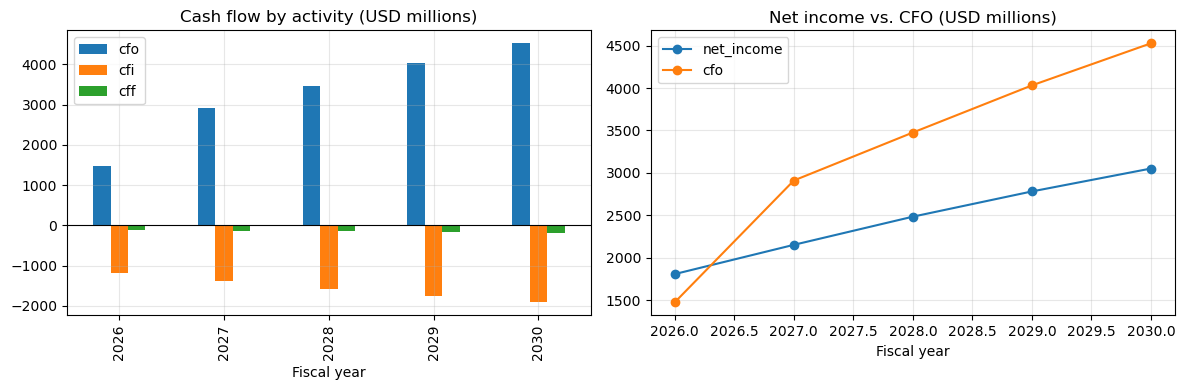

In [12]:
# Cash flow decomposition and the net income-to-CFO gap (provided)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cash_flow[["cfo", "cfi", "cff"]].plot(kind="bar", ax=axes[0], title=f"Cash flow by activity ({UNITS})")
axes[0].axhline(0, color="black", linewidth=0.8)
cash_flow[["net_income", "cfo"]].plot(ax=axes[1], marker="o", title=f"Net income vs. CFO ({UNITS})")
for ax in axes:
    ax.set_xlabel("Fiscal year"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Scenario test.** Show that the model is scenario-ready: copy `DRIVERS`, change one driver (for example, DSO up 10 days or a share repurchase of 1,000 in year 1), and call `run_three_statement_model()` once. The tie-outs must still hold.

In [13]:
# Scenario: DSO +10 days (105 -> 115). One changed driver, one call to the entry point.
drivers_dso = {**DRIVERS, "dso": DRIVERS["dso"] + 10}
scen = run_three_statement_model(is_forecast, opening_bs, drivers_dso, scenario="dso_plus_10")

compare = pd.DataFrame({
    "base_cash_end": cash_flow["cash_end"],
    "scenario_cash_end": scen["cash_flow"]["cash_end"],
    "base_fcff": fcf["fcff"],
    "scenario_fcff": scen["fcf"]["fcff"],
})
compare["cash_change"] = compare["scenario_cash_end"] - compare["base_cash_end"]
compare["fcff_change"] = compare["scenario_fcff"] - compare["base_fcff"]
display(compare.round(1))

# Hand check: year-5 cash falls by the extra receivables, 10/365 x FY2030 revenue
y5 = cash_flow.index[-1]
expected = -10 / DAYS * is_forecast.loc[y5, IS_COLS["revenue"]]
print(f"Year-5 cash change: {compare.loc[y5, 'cash_change']:,.1f} vs. hand check {expected:,.1f}")
print("Scenario flags all False:", not scen["integrity"].filter(like="Flag_").any().any())

,base_cash_end,scenario_cash_end,base_fcff,scenario_fcff,cash_change,fcff_change
fiscal_year,,,,,,
2026,624.3,-457.7,507.7,-574.3,-1082.0,-1082.0
2027,2020.2,754.2,1739.4,1555.5,-1266.0,-183.9
2028,3767.0,2323.8,2110.3,1933.1,-1443.2,-177.2
2029,5877.2,4275.2,2491.4,2332.7,-1601.9,-158.8
2030,8308.6,6562.5,2828.9,2684.7,-1746.1,-144.2


Year-5 cash change: -1,746.1 vs. hand check -1,746.1
Scenario flags all False: True


In [14]:
# Fail-fast test: shift opening cash by 1.0 without an offsetting entry; the model must refuse to run.
broken_bs = opening_bs.copy()
broken_bs["cash"] += 1.0
try:
    run_three_statement_model(is_forecast, broken_bs, DRIVERS)
    print("ERROR: model ran on an unbalanced opening balance sheet")
except ValueError as e:
    print("fail_fast raised as expected:", str(e).split(".")[0])

fail_fast raised as expected: Opening balance sheet (FY2025) is off by 1


✍️ **Interpretation (3–5 sentences):** Why do net income and CFO differ in your forecast? What do FCFF and the FCFE proxy say about the firm's capacity to fund dividends, repurchases, or debt repayment? What did the scenario test show?

Net income exceeds CFO only in FY2026 (1,810.1 vs. 1,478.2): the D&A add-back of 1,263.8 is more than offset by a 1,595.7 working-capital build, mostly receivables growing with the jump in Week 3 revenue. From FY2027 on, CFO runs 35–48% above net income because D&A outweighs the smaller working-capital builds. FCFF rises from 507.7 to 2,828.9, and the FCFE proxy equals FCFF because debt is held flat, so dividends (108.6 in FY2026) are covered several times over and the model leaves large capacity for repurchases, acquisitions, or debt repayment. The DSO +10 scenario cut FY2026 FCFF by 1,082.0 and year-5 cash by 1,746.1 (from 8,308.6 to 6,562.5), pushed FY2026 cash to −457.7, and left every tie-out within tolerance.

---
## 2.9 Export Readiness

Write your summary below, then run the export cell (provided). It saves the cash flow statement (history from FMP's quarterly statements aggregated to fiscal years, plus your forecast, labeled "A" and "E"; the historical rows use FMP's cash definition, so the last actual `Cash_End` may not equal the first forecast `Cash_Begin`, as you explained in 2.1), the updated balance sheet with `BalanceError`, the integrity report with its flags and maximum errors, a metadata sidecar, and your summary.

### Summary report

Write your summary in the `SUMMARY` string (Markdown); it displays here and exports as `_summary.md`. In under one page, cover:

1. **Model structure:** the builders, the one-run function, and the sign conventions.
2. **Driver assumptions:** and any changes from Week 4.
3. **Cash flow decomposition:** CFO versus CFI versus CFF.
4. **Net income versus CFO:** what explains the gap.
5. **FCFF and FCFE proxy:** definitions used and what they imply.
6. **Principal risks:** where the integrated model is most likely wrong.

In [15]:
SUMMARY = """
## Chapter 5 Mini-Project Summary: Quanta Services (PWR)

**Model structure.** The model integrates the Week 3 income statement (FY2026-FY2030) with the Week 4 schedules, starting from the FY2025 fiscal Q4 balance sheet, in USD millions. Historical cash flows come from 24 quarters of FMP statements (FY2020Q3-FY2026Q2), aggregated to FY2021-FY2025; both data checks pass. One call to `run_three_statement_model()` runs the builders in order: income statement, schedules (working capital, PP&E, equity, debt), balance sheet ex-cash, CFO/CFI/CFF, cash roll-forward, full balance sheet, and integrity checks. Cash is rolled forward from 439.5 and inserted into the balance sheet, never solved as a plug. Inflows are positive and outflows negative; CapEx, repayments, repurchases, and dividends are stored as positive magnitudes and signed at assembly. Interest stays in CFO and dividends in CFF. With `fail_fast=True`, any flag above ATOL (1e-6) raises an error; the maximum balance error is 7.3e-12, and rolled cash matches the Week 4 plug exactly.

**Driver assumptions.** Unchanged from Week 4: DSO 105, DIO 4.5, DPO 38.5, contract liabilities 10% of revenue, CapEx 3.0% of revenue, payout 6% of net income, interest 4.8%, and debt flat at 6,419 with no issuance, repurchases, or repayments.

**Cash flow decomposition.** Over FY2026-FY2030, CFO totals 16,424, CFI -7,817 (CapEx only), and CFF -738 (dividends only), so cash builds from 439.5 to 8,308.6.

**Net income versus CFO.** In FY2026, CFO (1,478.2) is below net income (1,810.1) because a 1,595.7 working-capital build, mostly receivables, outweighs the 1,263.8 D&A add-back. From FY2027, CFO exceeds net income by 35-48% as D&A outweighs smaller working-capital builds.

**FCFF and FCFE proxy.** FCFF = EBIT(1 - tax rate) + D&A - gross CapEx - change in NWC, with the tax rate from Week 3 (about 23.5%). The FCFE proxy adds net borrowing before dividends; with flat debt it equals FCFF. FCFF rises from 507.7 to 2,828.9 and totals 9,677.7, versus 737.3 of dividends, implying substantial capacity for acquisitions, repurchases, or debt repayment. FCFF exceeds CFO + CFI by after-tax net interest (214.3 per year).

**Principal risks.** The model has no acquisitions or buybacks, though Quanta spent about 3.3 billion on acquisitions and investments and 134.6 on repurchases in FY2025, so the 8.3 billion cash build overstates likely cash. D&A includes acquisition amortization but runs through PP&E, so net PP&E shrinks. Net income is fixed from Week 3, so interest does not respond to scenario debt changes. Cash is very sensitive to collections: DSO +10 days cuts year-5 cash by 1,746.1 and turns FY2026 cash negative (-457.7).
"""

from IPython.display import Markdown
display(Markdown(SUMMARY))


## Chapter 5 Mini-Project Summary: Quanta Services (PWR)

**Model structure.** The model integrates the Week 3 income statement (FY2026-FY2030) with the Week 4 schedules, starting from the FY2025 fiscal Q4 balance sheet, in USD millions. Historical cash flows come from 24 quarters of FMP statements (FY2020Q3-FY2026Q2), aggregated to FY2021-FY2025; both data checks pass. One call to `run_three_statement_model()` runs the builders in order: income statement, schedules (working capital, PP&E, equity, debt), balance sheet ex-cash, CFO/CFI/CFF, cash roll-forward, full balance sheet, and integrity checks. Cash is rolled forward from 439.5 and inserted into the balance sheet, never solved as a plug. Inflows are positive and outflows negative; CapEx, repayments, repurchases, and dividends are stored as positive magnitudes and signed at assembly. Interest stays in CFO and dividends in CFF. With `fail_fast=True`, any flag above ATOL (1e-6) raises an error; the maximum balance error is 7.3e-12, and rolled cash matches the Week 4 plug exactly.

**Driver assumptions.** Unchanged from Week 4: DSO 105, DIO 4.5, DPO 38.5, contract liabilities 10% of revenue, CapEx 3.0% of revenue, payout 6% of net income, interest 4.8%, and debt flat at 6,419 with no issuance, repurchases, or repayments.

**Cash flow decomposition.** Over FY2026-FY2030, CFO totals 16,424, CFI -7,817 (CapEx only), and CFF -738 (dividends only), so cash builds from 439.5 to 8,308.6.

**Net income versus CFO.** In FY2026, CFO (1,478.2) is below net income (1,810.1) because a 1,595.7 working-capital build, mostly receivables, outweighs the 1,263.8 D&A add-back. From FY2027, CFO exceeds net income by 35-48% as D&A outweighs smaller working-capital builds.

**FCFF and FCFE proxy.** FCFF = EBIT(1 - tax rate) + D&A - gross CapEx - change in NWC, with the tax rate from Week 3 (about 23.5%). The FCFE proxy adds net borrowing before dividends; with flat debt it equals FCFF. FCFF rises from 507.7 to 2,828.9 and totals 9,677.7, versus 737.3 of dividends, implying substantial capacity for acquisitions, repurchases, or debt repayment. FCFF exceeds CFO + CFI by after-tax net interest (214.3 per year).

**Principal risks.** The model has no acquisitions or buybacks, though Quanta spent about 3.3 billion on acquisitions and investments and 134.6 on repurchases in FY2025, so the 8.3 billion cash build overstates likely cash. D&A includes acquisition amortization but runs through PP&E, so net PP&E shrinks. Net income is fixed from Week 3, so interest does not respond to scenario debt changes. Cash is very sensitive to collections: DSO +10 days cuts year-5 cash by 1,746.1 and turns FY2026 cash negative (-457.7).


In [16]:
# Export (provided)
from datetime import datetime, timezone
last_actual = int(opening_bs.name)
label = lambda years: [f"FY{y}{'A' if y <= last_actual else 'E'}" for y in years]
CF_EXPORT = {"cfo": "CFO", "cfi": "CFI", "cff": "CFF", "other_cash": "OtherCash",
             "net_change_in_cash": "NetChangeInCash", "cash_begin": "Cash_Begin", "cash_end": "Cash_End"}

cf_export = pd.concat([cf_hist[list(CF_EXPORT)], cash_flow[list(CF_EXPORT)]]).rename(columns=CF_EXPORT)
cf_export.index = label(cf_export.index); cf_export.index.name = "fiscal_year"
cf_export.round(2).to_csv(f"{FILE_STEM}_cash_flow.csv")

bs_hist = bs_week4.loc[bs_week4.index <= last_actual, balance_sheet.columns]
bs_export = pd.concat([bs_hist, balance_sheet]).rename(columns={"balance_error": "BalanceError"})
bs_export.index = label(bs_export.index); bs_export.index.name = "fiscal_year"
bs_export.round(2).to_csv(f"{FILE_STEM}_balance_sheet.csv")

integ_export = integrity.copy()
integ_export.index = label(integ_export.index); integ_export.index.name = "fiscal_year"
max_row = integrity.drop(columns=[c for c in integrity.columns if c.startswith("Flag_")]).abs().max()
integ_export.loc["max_abs_error"] = max_row
integ_export.to_csv(f"{FILE_STEM}_integrity.csv")

metadata = {**results["metadata"], "model_version": MODEL_VERSION, "company": SYMBOL,
            "income_statement_source": MP3_FORECAST_CSV, "opening_balance_source": MP4_BALANCE_CSV,
            "historical_cash_flow_source": "Financial Modeling Prep API (quarterly 10-Q/10-K cash flow statements, aggregated to fiscal years)",
            "historical_quarters": f"{cf_q.index[0]}-{cf_q.index[-1]}", "n_quarters": int(len(cf_q)),
            "data_checks_passed": bool((data_checks["result"] == "PASS").all()),
            "any_flag": bool(integrity.filter(like="Flag_").any().any()),
            "exported_utc": datetime.now(timezone.utc).isoformat(timespec="seconds")}
with open(f"{FILE_STEM}_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)
with open(f"{FILE_STEM}_summary.md", "w") as f:
    f.write(SUMMARY.strip() + "\n")

print("Exported:", ", ".join(f"{FILE_STEM}_{s}" for s in ["cash_flow.csv", "balance_sheet.csv", "integrity.csv", "metadata.json", "summary.md"]))
display(cf_export.T.round(1))
display(integ_export)

Exported: FIN6465_MP5_D'Antonio_Caleb_cash_flow.csv, FIN6465_MP5_D'Antonio_Caleb_balance_sheet.csv, FIN6465_MP5_D'Antonio_Caleb_integrity.csv, FIN6465_MP5_D'Antonio_Caleb_metadata.json, FIN6465_MP5_D'Antonio_Caleb_summary.md


fiscal_year,FY2021A,FY2022A,FY2023A,FY2024A,FY2025A,FY2026E,FY2027E,FY2028E,FY2029E,FY2030E
CFO,582.4,1130.3,1576.0,2081.2,2230.0,1478.2,2911.4,3476.3,4031.3,4526.6
CFI,-2898.6,-617.2,-989.6,-2294.3,-3831.0,-1184.8,-1386.2,-1580.3,-1754.1,-1912.0
CFF,2360.9,-311.1,268.5,-305.6,1275.0,-108.6,-129.3,-149.2,-167.0,-183.2
OtherCash,0.4,-0.7,7.0,-30.3,21.4,0.0,0.0,0.0,0.0,0.0
NetChangeInCash,45.1,201.3,861.8,-549.0,-304.6,184.8,1395.9,1746.9,2110.1,2431.4
Cash_Begin,186.8,231.9,433.2,1295.0,746.0,439.5,624.3,2020.2,3767.0,5877.2
Cash_End,231.9,433.2,1293.9,746.0,440.9,624.3,2020.2,3767.0,5877.2,8308.6


,cf_identity_error,cash_roll_error,cash_bs_tie_error,balance_error,Flag_CashMismatch,Flag_CashRollError,Flag_BSNotClosing
fiscal_year,,,,,,,
FY2026E,0.0,0.0,0.0,0.000000e+00,0.0,0.0,0.0
FY2027E,0.0,0.0,0.0,-3.637979e-12,0.0,0.0,0.0
FY2028E,0.0,0.0,0.0,5.456968e-12,0.0,0.0,0.0
FY2029E,0.0,0.0,0.0,-3.637979e-12,0.0,0.0,0.0
FY2030E,0.0,0.0,0.0,7.275958e-12,0.0,0.0,0.0
max_abs_error,0.0,0.0,0.0,7.275958e-12,NaN,NaN,NaN


---
## Results card

Record your key results. **Next Tuesday's iClicker quiz covers the Chapter 6 reading and this mini-project, including your own results and code.**

| Result | Your value |
|---|---|
| Company, ticker, beginning cash and its definition |Quanta Services (PWR); 439.5 USD millions; cash and short-term investments (= cash and cash equivalents) at FY2025 fiscal Q4, excluding 1.4 of restricted cash |
| Quarters used (first-last, count) and the CFO quarter-to-annual tie-out gap |FY2020Q3–FY2026Q2, 24 quarters; FY2025 CFO 2,230.0 vs. 10-K 2,230.0 (0.000%) |
| Year-1 CFO, CFI, and CFF |1,478.2; −1,184.8; −108.6 |
| Year-1 net income versus CFO, and the main reason for the gap |1,810.1 vs. 1,478.2; 1,595.7 working-capital build (receivables) exceeds the 1,263.8 D&A add-back |
| Year-5 cash (rolled) and the Week 4 cross-check difference |8,308.6; difference 0.000 in every year |
| Maximum absolute balance error |7.3e-12 |
| Year-1 FCFF and FCFE proxy |507.7; 507.7 (no net borrowing) |
| Scenario tested and its effect on year-5 cash |DSO +10 days (105 → 115); year-5 cash −1,746.1 (to 6,562.5); FY2026 cash −457.7 |

---
## AI-use reflection

Answer briefly. If you used no AI, write "No AI used" and answer question 3 only.

1. **Where did AI help?**
2. **Where was AI wrong or unhelpful?**
3. **What did you verify yourself?** 

1) I used Claude to structure the builder functions, write the integrity and fail-fast logic, diagnose why the opening balance sheet was off by 0.03.
2) Claude wrote IS_COLS before seeing my Week 3 column names, so I relied on the built-in check that raises an error if a name does not match. Its first instruction for re-exporting the Week 4 balance sheet also skipped running the notebook first, which gave a NameError until I ran all cells.
3) I recomputed FY2026 CFO by hand (1,810.1 + 1,263.8 − 1,595.7 = 1,478.2), confirmed rolled cash matches the Week 4 plug with a difference of 0.000, checked the scenario against 10/365 × FY2030 revenue (−1,746.1), and broke the opening balance sheet on purpose (+1.0 cash) to confirm fail_fast raises an error.

---
### Before you submit

- [ ] Every `# TODO` is completed and every ✍️ prompt answered
- [ ] Every required output has the exact names and columns listed
- [ ] All results come from one call to `run_three_statement_model()`, with `fail_fast=True`
- [ ] No cash plug: cash is rolled forward and inserted into the balance sheet
- [ ] Tie-outs hold within `ATOL`, and the Week 4 cross-check is explained
- [ ] At least 20 quarters loaded (`N_QUARTERS`), and the quarterly coverage and tie-out data checks pass (or the FAIL is explained)
- [ ] `SUMMARY` written and exported
- [ ] Student information, **results card**, and **AI-use reflection** completed
- [ ] Your team's API key does **not** appear anywhere in the notebook
- [ ] **Kernel → Restart Kernel and Run All Cells** runs without errors
- [ ] Uploaded in Canvas: `FIN6465_MP5_LastName_FirstName.ipynb`, `_cash_flow.csv`, `_balance_sheet.csv`, `_integrity.csv`, `_metadata.json`, and `_summary.md`